Libraries imported successfully!

STEP 2: UPLOAD STROKE DATASET


Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv
Dataset loaded successfully!
Dataset shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1



STEP 3: CHECKING MISSING VALUES
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Total missing values: 201

STEP 4: HANDLING MISSING BMI VALUES
Missing BMI values filled successfully!
Remaining missing values: 0

STEP 5: NUMERIC VARIABLE DISTRIBUTION


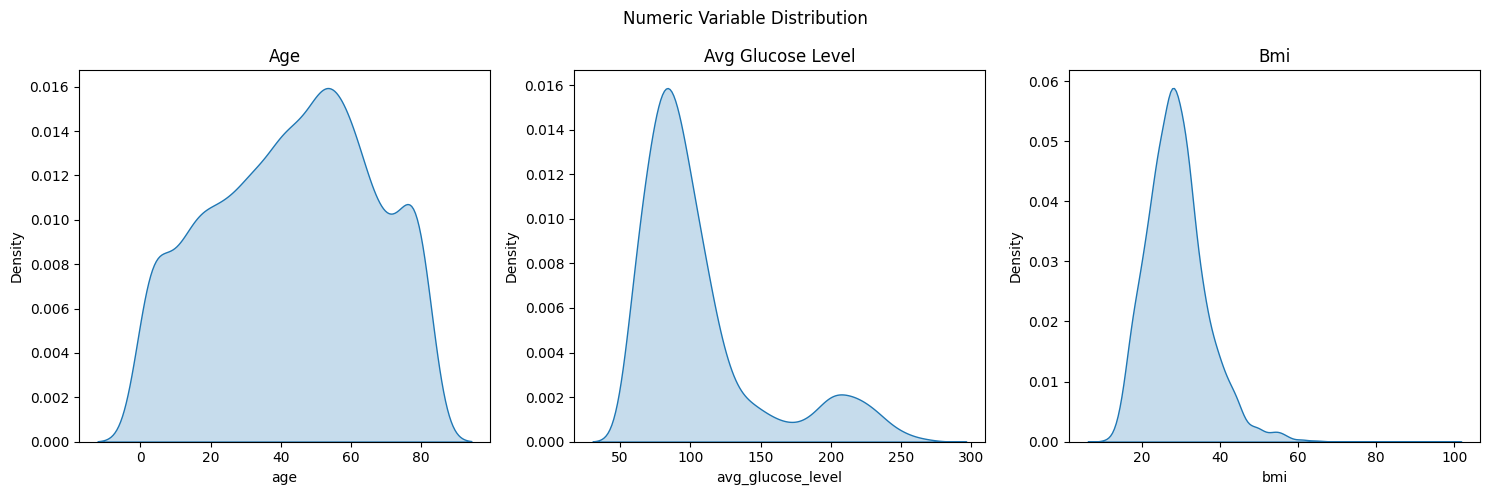


STEP 6: NUMERIC VARIABLES BY STROKE AND NO STROKE


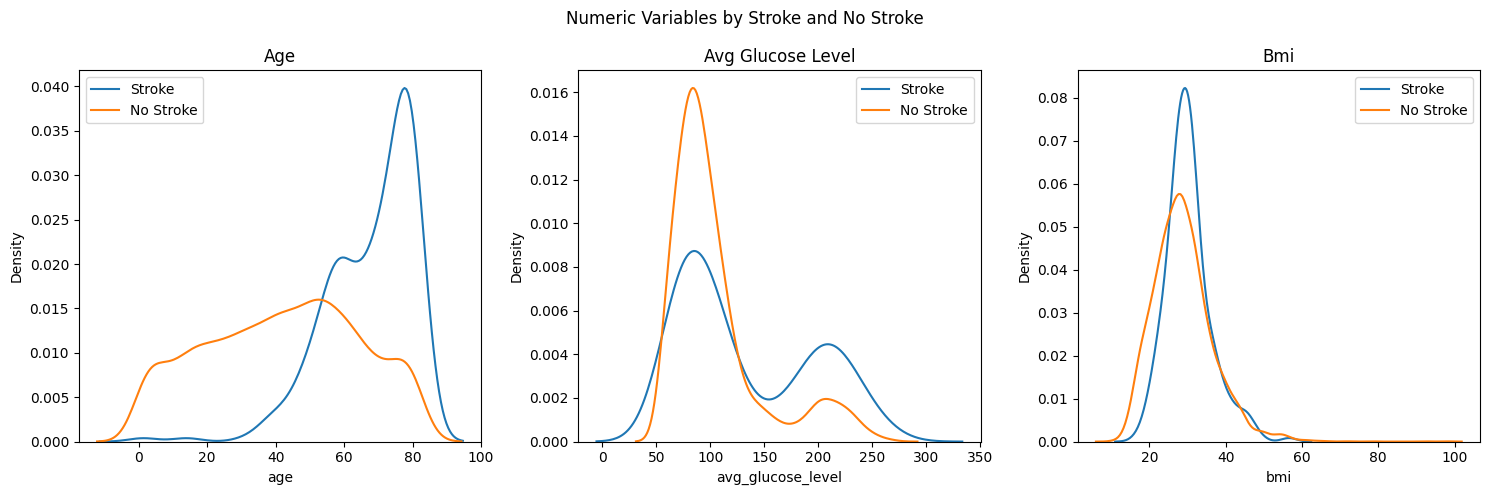


STEP 7: STROKE RISK BY AGE


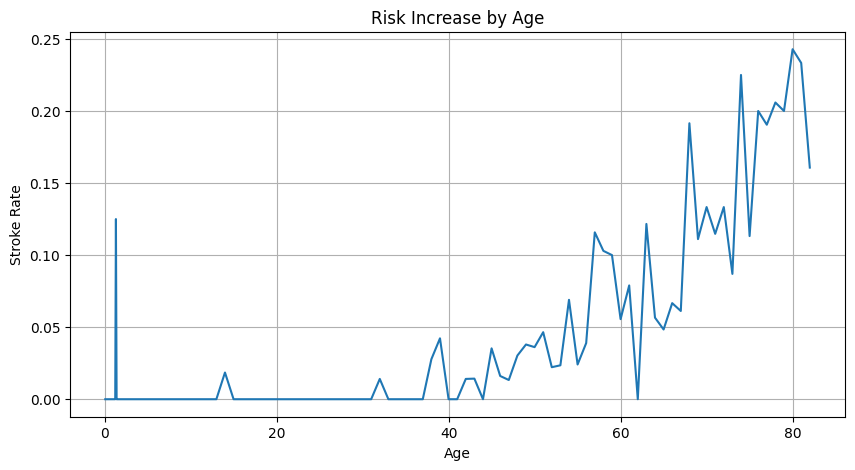


STEP 8: STROKE DISTRIBUTION
No Stroke: 4861
Stroke: 249


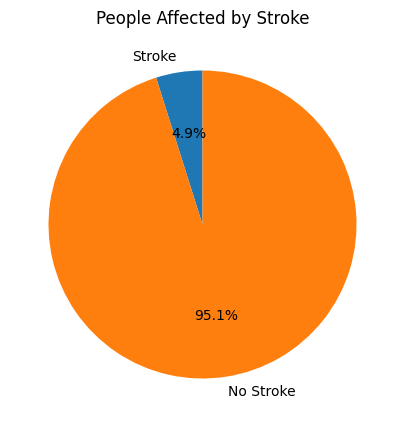


STEP 9: ENCODING CATEGORICAL VARIABLES
Categorical variables encoded successfully!


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,0,67,0,1,1,0,1,228.69,36.600000,0,1
1,51676,1,61,0,0,1,1,0,202.21,29.879487,1,1
2,31112,0,80,0,1,1,0,0,105.92,32.500000,1,1
3,60182,1,49,0,0,1,0,1,171.23,34.400000,2,1
4,1665,1,79,1,0,1,1,0,174.12,24.000000,1,1



STEP 10: PREPARING DATA FOR MODELING
Features: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']
Target variable: stroke

Inverse of Null Accuracy: 0.0487
Null Accuracy: 0.9513

STEP 11: TRAIN TEST SPLIT
Training data: (1533, 10)
Testing data: (3577, 10)

STEP 12: APPLYING SMOTE

Before SMOTE:
stroke
0    1458
1      75
Name: count, dtype: int64

After SMOTE:
stroke
0    1458
1    1458
Name: count, dtype: int64

STEP 13: CREATING MACHINE LEARNING MODELS

STEP 14: CROSS VALIDATION
Random Forest Mean F1 Score: 0.965
SVM Mean F1 Score: 0.8868
Logistic Regression Mean F1 Score: 0.8259

Best Model: Random Forest

STEP 15: MODEL TESTING

 Random Forest
Accuracy: 0.9186
F1 Score: 0.1313

 SVM
Accuracy: 0.7948
F1 Score: 0.1952

 Logistic Regression
Accuracy: 0.7545
F1 Score: 0.2298

STEP 16: RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       

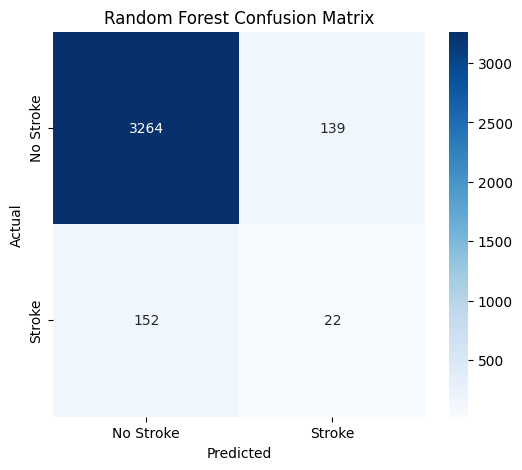


STEP 17: RANDOM FOREST TUNING

Tuned Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96      3403
           1       0.12      0.10      0.11       174

    accuracy                           0.92      3577
   macro avg       0.54      0.53      0.53      3577
weighted avg       0.91      0.92      0.92      3577

Accuracy Score: 0.9203242941012021
F1 Score: 0.10658307210031348

STEP 18: LOGISTIC REGRESSION TUNING

Best Parameters:
{'C': 0.01, 'penalty': 'l1', 'solver': 'liblinear'}

Tuned Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.68      0.81      3403
           1       0.12      0.84      0.21       174

    accuracy                           0.69      3577
   macro avg       0.55      0.76      0.51      3577
weighted avg       0.95      0.69      0.78      3577

Accuracy Score: 0.6899636566955549
F1 Score: 0.20

In [1]:

# EXPERIMENT 8: PREDICTING STROKE USING MACHINE LEARNING

# STEP 1: INSTALL AND IMPORT LIBRARIES

!pip -q install imbalanced-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from google.colab import files

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, f1_score
)

from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

# STEP 2: UPLOAD AND LOAD STROKE DATASET

print("\nSTEP 2: UPLOAD STROKE DATASET")

uploaded = files.upload()

csv_files = [f for f in uploaded.keys() if f.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload a CSV file.")

df = pd.read_csv(csv_files[0])

required_columns = [
    "id", "gender", "age", "hypertension", "heart_disease",
    "ever_married", "work_type", "Residence_type",
    "avg_glucose_level", "bmi", "smoking_status", "stroke"
]

missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError("Missing columns: " + str(missing_columns))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

# STEP 3: CHECK MISSING VALUES

print("\nSTEP 3: CHECKING MISSING VALUES")

print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# STEP 4: HANDLE MISSING BMI VALUES USING DECISION TREE

print("\nSTEP 4: HANDLING MISSING BMI VALUES")

# Encode gender temporarily for BMI prediction
gender_map = {
    "Male": 0,
    "Female": 1,
    "Other": -1
}

df["gender_encoded"] = df["gender"].map(gender_map)

# Separate records with and without missing BMI
known_bmi = df[df["bmi"].notna()].copy()
missing_bmi = df[df["bmi"].isna()].copy()

if len(missing_bmi) > 0:
    bmi_model = DecisionTreeRegressor(random_state=42)

    bmi_model.fit(
        known_bmi[["age", "gender_encoded"]],
        known_bmi["bmi"]
    )

    predicted_bmi = bmi_model.predict(
        missing_bmi[["age", "gender_encoded"]]
    )

    df.loc[df["bmi"].isna(), "bmi"] = predicted_bmi

df.drop(columns=["gender_encoded"], inplace=True)

print("Missing BMI values filled successfully!")
print("Remaining missing values:", df.isnull().sum().sum())

# STEP 5: EXPLORE NUMERIC VARIABLES

print("\nSTEP 5: NUMERIC VARIABLE DISTRIBUTION")

background_color = "#fafafa"

continuous_variables = [
    "age", "avg_glucose_level", "bmi"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, variable in enumerate(continuous_variables):
    sns.kdeplot(
        data=df,
        x=variable,
        fill=True,
        ax=axes[i]
    )
    axes[i].set_title(variable.replace("_", " ").title())

plt.suptitle("Numeric Variable Distribution")
plt.tight_layout()
plt.show()

# STEP 6: COMPARE NUMERIC VARIABLES BY STROKE

print("\nSTEP 6: NUMERIC VARIABLES BY STROKE AND NO STROKE")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, variable in enumerate(continuous_variables):
    sns.kdeplot(
        data=df[df["stroke"] == 1],
        x=variable,
        label="Stroke",
        fill=False,
        ax=axes[i]
    )

    sns.kdeplot(
        data=df[df["stroke"] == 0],
        x=variable,
        label="No Stroke",
        fill=False,
        ax=axes[i]
    )

    axes[i].set_title(variable.replace("_", " ").title())
    axes[i].legend()

plt.suptitle("Numeric Variables by Stroke and No Stroke")
plt.tight_layout()
plt.show()

# STEP 7: ANALYZE STROKE RISK BY AGE

print("\nSTEP 7: STROKE RISK BY AGE")

age_risk = df.groupby("age")["stroke"].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=age_risk.index, y=age_risk.values)
plt.title("Risk Increase by Age")
plt.xlabel("Age")
plt.ylabel("Stroke Rate")
plt.grid(True)
plt.show()

# STEP 8: DISPLAY STROKE DISTRIBUTION

print("\nSTEP 8: STROKE DISTRIBUTION")

stroke_counts = df["stroke"].value_counts()

print("No Stroke:", stroke_counts.get(0, 0))
print("Stroke:", stroke_counts.get(1, 0))

plt.figure(figsize=(7, 5))

plt.pie(
    [stroke_counts.get(1, 0), stroke_counts.get(0, 0)],
    labels=["Stroke", "No Stroke"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("People Affected by Stroke")
plt.show()

# STEP 9: ENCODE CATEGORICAL VARIABLES

print("\nSTEP 9: ENCODING CATEGORICAL VARIABLES")

df["gender"] = df["gender"].map({
    "Male": 0,
    "Female": 1,
    "Other": -1
})

df["ever_married"] = df["ever_married"].map({
    "No": 0,
    "Yes": 1
})

df["Residence_type"] = df["Residence_type"].map({
    "Rural": 0,
    "Urban": 1
})

df["work_type"] = df["work_type"].map({
    "Private": 0,
    "Self-employed": 1,
    "Govt_job": 2,
    "children": 3,
    "Never_worked": 4
})

df["smoking_status"] = df["smoking_status"].map({
    "formerly smoked": 0,
    "never smoked": 1,
    "smokes": 2,
    "Unknown": 3
})

df["age"] = df["age"].astype(int)

print("Categorical variables encoded successfully!")
display(df.head())

# STEP 10: PREPARE DATA FOR MACHINE LEARNING

print("\nSTEP 10: PREPARING DATA FOR MODELING")

X = df.drop(columns=["id", "stroke"])
y = df["stroke"].astype(int)

print("Features:", X.columns.tolist())
print("Target variable: stroke")

print("\nInverse of Null Accuracy:",
      round(y.mean(), 4))

print("Null Accuracy:",
      round(1 - y.mean(), 4))

# STEP 11: SPLIT DATA INTO TRAINING AND TESTING SETS

print("\nSTEP 11: TRAIN TEST SPLIT")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.3,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# STEP 12: APPLY SMOTE TO BALANCE TRAINING DATA

print("\nSTEP 12: APPLYING SMOTE")

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

smote = SMOTE(random_state=42)

X_train_resh, y_train_resh = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("\nBefore SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_resh).value_counts())

# STEP 13: CREATE MACHINE LEARNING MODELS

print("\nSTEP 13: CREATING MACHINE LEARNING MODELS")

rf_pipeline = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

svm_pipeline = SVC(
    random_state=42
)

logreg_pipeline = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# STEP 14: CROSS VALIDATION AND MODEL COMPARISON

print("\nSTEP 14: CROSS VALIDATION")

models = {
    "Random Forest": rf_pipeline,
    "SVM": svm_pipeline,
    "Logistic Regression": logreg_pipeline
}

model_scores = {}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train_resh,
        y_train_resh,
        cv=5,
        scoring="f1",
        n_jobs=-1
    )

    model_scores[name] = scores.mean()

    print(name, "Mean F1 Score:", round(scores.mean(), 4))

print("\nBest Model:", max(model_scores, key=model_scores.get))

# STEP 15: TRAIN MODELS AND TEST ON UNSEEN DATA

print("\nSTEP 15: MODEL TESTING")

predictions = {}

for name, model in models.items():

    model.fit(X_train_resh, y_train_resh)

    pred = model.predict(X_test_scaled)

    predictions[name] = pred

    print("\n", name)
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print("F1 Score:", round(f1_score(y_test, pred, zero_division=0), 4))

# STEP 16: RANDOM FOREST EVALUATION

print("\nSTEP 16: RANDOM FOREST CLASSIFICATION REPORT")

rf_pred = predictions["Random Forest"]

print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))

rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Stroke", "Stroke"],
    yticklabels=["No Stroke", "Stroke"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# STEP 17: TUNE RANDOM FOREST MODEL

print("\nSTEP 17: RANDOM FOREST TUNING")

rfc = RandomForestClassifier(
    max_features=2,
    n_estimators=100,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

rfc.fit(X_train_resh, y_train_resh)

rfc_tuned_pred = rfc.predict(X_test_scaled)

print("\nTuned Random Forest Classification Report:")
print(classification_report(
    y_test,
    rfc_tuned_pred,
    zero_division=0
))

print("Accuracy Score:",
      accuracy_score(y_test, rfc_tuned_pred))

print("F1 Score:",
      f1_score(y_test, rfc_tuned_pred, zero_division=0))

# STEP 18: LOGISTIC REGRESSION HYPERPARAMETER TUNING

print("\nSTEP 18: LOGISTIC REGRESSION TUNING")

log_param_grid = {
    "penalty": ["l1", "l2"],
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear"]
}

grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    log_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train_resh, y_train_resh)

logreg_tuned_pred = grid.best_estimator_.predict(X_test_scaled)

print("\nBest Parameters:")
print(grid.best_params_)

print("\nTuned Logistic Regression Classification Report:")
print(classification_report(
    y_test,
    logreg_tuned_pred,
    zero_division=0
))

print("Accuracy Score:",
      accuracy_score(y_test, logreg_tuned_pred))

print("F1 Score:",
      f1_score(y_test, logreg_tuned_pred, zero_division=0))

# FINAL SUMMARY

print("\n==========================================")
print("EXPERIMENT 8 COMPLETED SUCCESSFULLY")
print("PREDICTING STROKE USING MACHINE LEARNING")
print("==========================================")

print("\nModel Comparison:")

for name, score in model_scores.items():
    print(name, ":", round(score, 4))


